In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import matplotlib as mpl
from matplotlib import cm
from matplotlib.colors import Colormap, LinearSegmentedColormap
import seaborn as sns

import pickle

In [2]:
tank_index = 12
hose_index = 18
tank_z_inv = 1.016
z_inv_1 = 0.6604

cms_to_gpm = 15850.3
gpm_to_lpm = 3.78541

mean_roughness = 1.4999999999999998e-06
feed_minor_loss = 35.87
return_minor_loss = 11.8

In [3]:
demand_flow = pd.read_csv('../data/fig_5_6/demand_flow.csv', index_col=0)
leak_flow = pd.read_csv('../data/fig_5_6/leak_flow.csv', index_col=0)
d1 = pd.read_csv('../data/fig_5_6/d1.csv', index_col=0)
n2 = pd.read_csv('../data/fig_5_6/n2.csv', index_col=0)
f1 = pd.read_csv('../data/fig_5_6/f1.csv', index_col=0)
f2 = pd.read_csv('../data/fig_5_6/f2.csv', index_col=0)

demand_flow.index = pd.to_datetime(demand_flow.index)
leak_flow.index = pd.to_datetime(leak_flow.index)
d1.index = pd.to_datetime(d1.index)
n2.index = pd.to_datetime(n2.index)
f1.index = pd.to_datetime(f1.index)
f2.index = pd.to_datetime(f2.index)

In [4]:
all_H_0 = np.load('../data/fig_5_6/all_H_0.npy')
all_Q_0 = np.load('../data/fig_5_6/all_Q_0.npy')
all_Qin_0 = np.load('../data/fig_5_6/all_Qin_0.npy')
all_Qo_0 = np.load('../data/fig_5_6/all_Qo_0.npy')
all_t_0 = np.load('../data/fig_5_6/all_t_0.npy')

all_H_1 = np.load('../data/fig_5_6/all_H_1.npy')
all_Q_1 = np.load('../data/fig_5_6/all_Q_1.npy')
all_Qin_1 = np.load('../data/fig_5_6/all_Qin_1.npy')
all_Qo_1 = np.load('../data/fig_5_6/all_Qo_1.npy')
all_t_1 = np.load('../data/fig_5_6/all_t_1.npy')

all_H_2 = np.load('../data/fig_5_6/all_H_2.npy')
all_Q_2 = np.load('../data/fig_5_6/all_Q_2.npy')
all_Qin_2 = np.load('../data/fig_5_6/all_Qin_2.npy')
all_Qo_2 = np.load('../data/fig_5_6/all_Qo_2.npy')
all_t_2 = np.load('../data/fig_5_6/all_t_2.npy')

all_H_3 = np.load('../data/fig_5_6/all_H_3.npy')
all_Q_3 = np.load('../data/fig_5_6/all_Q_3.npy')
all_Qin_3 = np.load('../data/fig_5_6/all_Qin_3.npy')
all_Qo_3 = np.load('../data/fig_5_6/all_Qo_3.npy')
all_t_3 = np.load('../data/fig_5_6/all_t_3.npy')

all_H_4 = np.load('../data/fig_5_6/all_H_4.npy')
all_Q_4 = np.load('../data/fig_5_6/all_Q_4.npy')
all_Qin_4 = np.load('../data/fig_5_6/all_Qin_4.npy')
all_Qo_4 = np.load('../data/fig_5_6/all_Qo_4.npy')
all_t_4 = np.load('../data/fig_5_6/all_t_4.npy')

In [5]:
all_Q_0 *= gpm_to_lpm
all_Qin_0 *= gpm_to_lpm
all_Qo_0 *= gpm_to_lpm

all_Q_1 *= gpm_to_lpm
all_Qin_1 *= gpm_to_lpm
all_Qo_1 *= gpm_to_lpm

all_Q_2 *= gpm_to_lpm
all_Qin_2 *= gpm_to_lpm
all_Qo_2 *= gpm_to_lpm

all_Q_3 *= gpm_to_lpm
all_Qin_3 *= gpm_to_lpm
all_Qo_3 *= gpm_to_lpm

all_Q_4 *= gpm_to_lpm
all_Qin_4 *= gpm_to_lpm
all_Qo_4 *= gpm_to_lpm

In [6]:
H_0_05pct = np.percentile(all_H_0, 5, axis=0)
H_0_25pct = np.percentile(all_H_0, 25, axis=0)
H_0_75pct = np.percentile(all_H_0, 75, axis=0)
H_0_95pct = np.percentile(all_H_0, 95, axis=0)

Q_0_05pct = np.percentile(all_Q_0, 5, axis=0)
Q_0_25pct = np.percentile(all_Q_0, 25, axis=0)
Q_0_75pct = np.percentile(all_Q_0, 75, axis=0)
Q_0_95pct = np.percentile(all_Q_0, 95, axis=0)

Qin_0_05pct = np.percentile(all_Qin_0, 5, axis=0)
Qin_0_25pct = np.percentile(all_Qin_0, 25, axis=0)
Qin_0_75pct = np.percentile(all_Qin_0, 75, axis=0)
Qin_0_95pct = np.percentile(all_Qin_0, 95, axis=0)

Qo_0_05pct = np.percentile(all_Qo_0, 5, axis=0)
Qo_0_25pct = np.percentile(all_Qo_0, 25, axis=0)
Qo_0_75pct = np.percentile(all_Qo_0, 75, axis=0)
Qo_0_95pct = np.percentile(all_Qo_0, 95, axis=0)

H_1_05pct = np.percentile(all_H_1, 5, axis=0)
H_1_25pct = np.percentile(all_H_1, 25, axis=0)
H_1_75pct = np.percentile(all_H_1, 75, axis=0)
H_1_95pct = np.percentile(all_H_1, 95, axis=0)

Q_1_05pct = np.percentile(all_Q_1, 5, axis=0)
Q_1_25pct = np.percentile(all_Q_1, 25, axis=0)
Q_1_75pct = np.percentile(all_Q_1, 75, axis=0)
Q_1_95pct = np.percentile(all_Q_1, 95, axis=0)

Qin_1_05pct = np.percentile(all_Qin_1, 5, axis=0)
Qin_1_25pct = np.percentile(all_Qin_1, 25, axis=0)
Qin_1_75pct = np.percentile(all_Qin_1, 75, axis=0)
Qin_1_95pct = np.percentile(all_Qin_1, 95, axis=0)

Qo_1_05pct = np.percentile(all_Qo_1, 5, axis=0)
Qo_1_25pct = np.percentile(all_Qo_1, 25, axis=0)
Qo_1_75pct = np.percentile(all_Qo_1, 75, axis=0)
Qo_1_95pct = np.percentile(all_Qo_1, 95, axis=0)

H_2_05pct = np.percentile(all_H_2, 5, axis=0)
H_2_25pct = np.percentile(all_H_2, 25, axis=0)
H_2_75pct = np.percentile(all_H_2, 75, axis=0)
H_2_95pct = np.percentile(all_H_2, 95, axis=0)

Q_2_05pct = np.percentile(all_Q_2, 5, axis=0)
Q_2_25pct = np.percentile(all_Q_2, 25, axis=0)
Q_2_75pct = np.percentile(all_Q_2, 75, axis=0)
Q_2_95pct = np.percentile(all_Q_2, 95, axis=0)

Qin_2_05pct = np.percentile(all_Qin_2, 5, axis=0)
Qin_2_25pct = np.percentile(all_Qin_2, 25, axis=0)
Qin_2_75pct = np.percentile(all_Qin_2, 75, axis=0)
Qin_2_95pct = np.percentile(all_Qin_2, 95, axis=0)

Qo_2_05pct = np.percentile(all_Qo_2, 5, axis=0)
Qo_2_25pct = np.percentile(all_Qo_2, 25, axis=0)
Qo_2_75pct = np.percentile(all_Qo_2, 75, axis=0)
Qo_2_95pct = np.percentile(all_Qo_2, 95, axis=0)

H_3_05pct = np.percentile(all_H_3, 5, axis=0)
H_3_25pct = np.percentile(all_H_3, 25, axis=0)
H_3_75pct = np.percentile(all_H_3, 75, axis=0)
H_3_95pct = np.percentile(all_H_3, 95, axis=0)

Q_3_05pct = np.percentile(all_Q_3, 5, axis=0)
Q_3_25pct = np.percentile(all_Q_3, 25, axis=0)
Q_3_75pct = np.percentile(all_Q_3, 75, axis=0)
Q_3_95pct = np.percentile(all_Q_3, 95, axis=0)

Qin_3_05pct = np.percentile(all_Qin_3, 5, axis=0)
Qin_3_25pct = np.percentile(all_Qin_3, 25, axis=0)
Qin_3_75pct = np.percentile(all_Qin_3, 75, axis=0)
Qin_3_95pct = np.percentile(all_Qin_3, 95, axis=0)

Qo_3_05pct = np.percentile(all_Qo_3, 5, axis=0)
Qo_3_25pct = np.percentile(all_Qo_3, 25, axis=0)
Qo_3_75pct = np.percentile(all_Qo_3, 75, axis=0)
Qo_3_95pct = np.percentile(all_Qo_3, 95, axis=0)

H_4_05pct = np.percentile(all_H_4, 5, axis=0)
H_4_25pct = np.percentile(all_H_4, 25, axis=0)
H_4_75pct = np.percentile(all_H_4, 75, axis=0)
H_4_95pct = np.percentile(all_H_4, 95, axis=0)

Q_4_05pct = np.percentile(all_Q_4, 5, axis=0)
Q_4_25pct = np.percentile(all_Q_4, 25, axis=0)
Q_4_75pct = np.percentile(all_Q_4, 75, axis=0)
Q_4_95pct = np.percentile(all_Q_4, 95, axis=0)

Qin_4_05pct = np.percentile(all_Qin_4, 5, axis=0)
Qin_4_25pct = np.percentile(all_Qin_4, 25, axis=0)
Qin_4_75pct = np.percentile(all_Qin_4, 75, axis=0)
Qin_4_95pct = np.percentile(all_Qin_4, 95, axis=0)

Qo_4_05pct = np.percentile(all_Qo_4, 5, axis=0)
Qo_4_25pct = np.percentile(all_Qo_4, 25, axis=0)
Qo_4_75pct = np.percentile(all_Qo_4, 75, axis=0)
Qo_4_95pct = np.percentile(all_Qo_4, 95, axis=0)

In [7]:
T = pd.read_csv('../data/fig_5_6/mc_timestamps.csv', index_col=0)
T = pd.to_datetime(T['timestamp'])

In [8]:
cmap = mpl.colormaps['YlGnBu'].resampled(7)
sensorcolor = 'fuchsia'

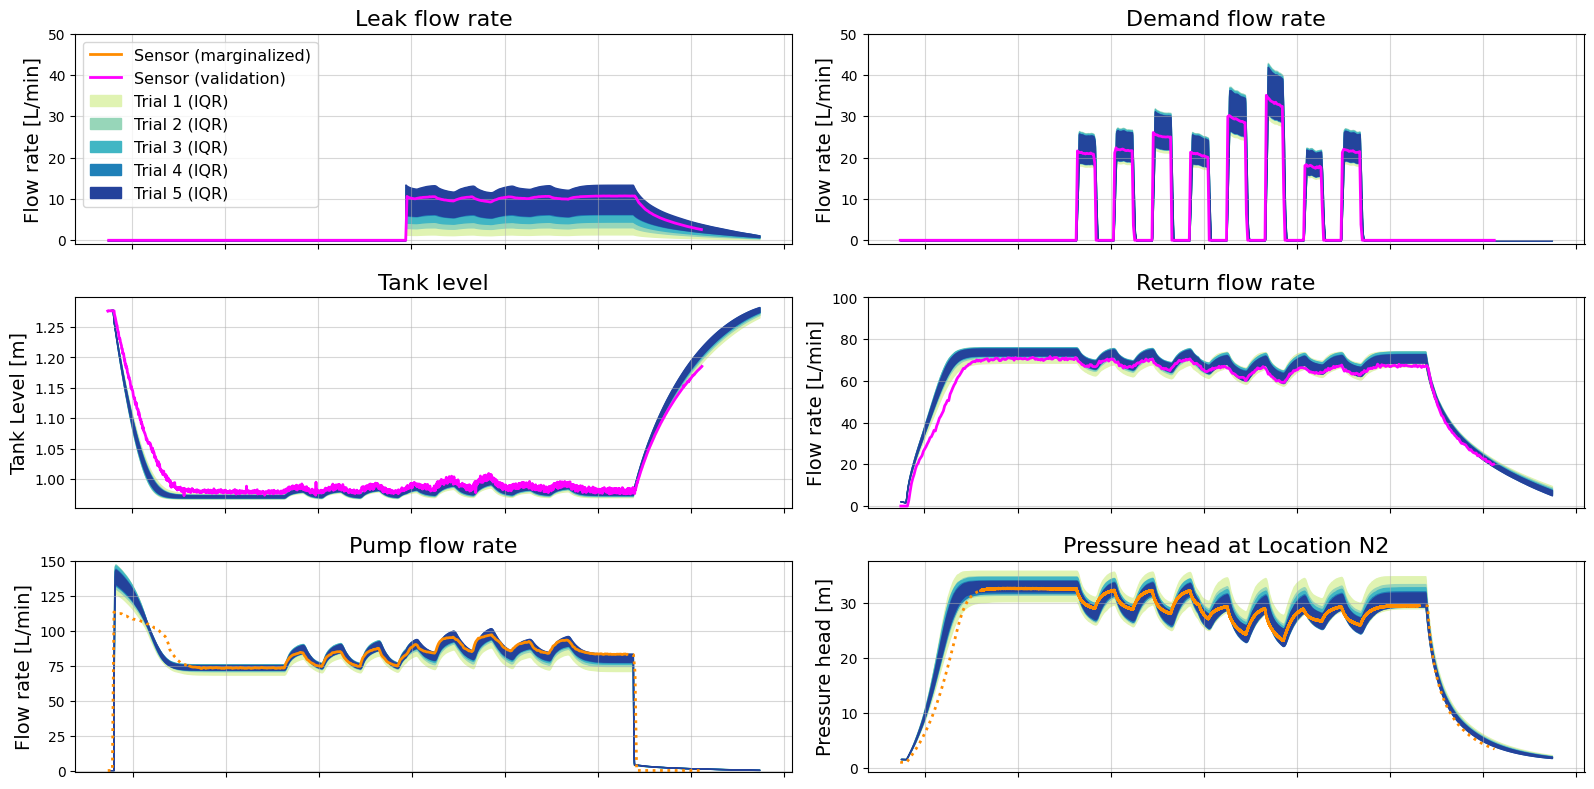

In [9]:
fig, ax = plt.subplots(3, 2, figsize=(16, 8))

demand_flow.loc[:, 'distinct'].plot(ax=ax[0, 1], label='Sensor (validation)', c=sensorcolor, alpha=1, linewidth=2)
ax[0,0].plot([], [], label='Sensor (marginalized)', c='darkorange', linewidth=2)
ax[0,1].fill_between(T.values, (Qin_0_75pct[:, 12]), (Qin_0_25pct[:, 12]),
                     label='Trial 1 (IQR)', color=cmap(1), alpha=0.95)
ax[0,1].fill_between(T.values, (Qin_1_75pct[:, 12]), (Qin_1_25pct[:, 12]),
                     label='Trial 2 (IQR)', color=cmap(2), alpha=0.95)
ax[0,1].fill_between(T.values, (Qin_2_75pct[:, 12]), (Qin_2_25pct[:, 12]),
                     label='Trial 3 (IQR)', color=cmap(3), alpha=0.95)
ax[0,1].fill_between(T.values, (Qin_3_75pct[:, 12]), (Qin_3_25pct[:, 12]),
                     label='Trial 4 (IQR)', color=cmap(4), alpha=0.95)
ax[0,1].fill_between(T.values, (Qin_4_75pct[:, 12]), (Qin_4_25pct[:, 12]),
                     label='Trial 5 (IQR)', color=cmap(5), alpha=0.95)
ax[0,1].set_ylabel('Flow rate [L/min]', size=14)
ax[0,1].grid(alpha=0.5)
ax[0,1].set_title('Demand flow rate', size=16)
ax[0,1].set_ylim(-1, 50)
ax[0,1].xaxis.set_ticklabels([])

leak_flow.loc[:, 'distinct'].plot(ax=ax[0, 0], label='Sensor (validation)', c=sensorcolor, alpha=1, linewidth=2)
ax[0,0].fill_between(T.values, (Qo_0_75pct[:, 0]), (Qo_0_25pct[:, 0]),
                     label='Trial 1 (IQR)', color=cmap(1), alpha=1)
ax[0,0].fill_between(T.values, (Qo_1_75pct[:, 0]), (Qo_1_25pct[:, 0]),
                     label='Trial 2 (IQR)', color=cmap(2), alpha=1)
ax[0,0].fill_between(T.values, (Qo_2_75pct[:, 0]), (Qo_2_25pct[:, 0]),
                     label='Trial 3 (IQR)', color=cmap(3), alpha=1)
ax[0,0].fill_between(T.values, (Qo_3_75pct[:, 0]), (Qo_3_25pct[:, 0]),
                     label='Trial 4 (IQR)', color=cmap(4), alpha=1)
ax[0,0].fill_between(T.values, (Qo_4_75pct[:, 0]), (Qo_4_25pct[:, 0]),
                     label='Trial 5 (IQR)', color=cmap(5), alpha=1)
ax[0,0].set_ylabel('Flow rate [L/min]', size=14)
ax[0,0].legend(loc=2, fontsize=11.5)
ax[0,0].grid(alpha=0.5)
ax[0,0].set_title('Leak flow rate', size=16)
ax[0,0].set_ylim(-1, 50)
ax[0,0].xaxis.set_ticklabels([])

d1.loc[:, 'distinct'].plot(ax=ax[1, 0], label='Sensor (validation)', c=sensorcolor, alpha=1, linewidth=2)
ax[1,0].fill_between(T.values, (H_0_75pct[:, tank_index] - tank_z_inv), (H_0_25pct[:, tank_index] - tank_z_inv),
                     label='trial 1', color=cmap(1), alpha=1)
ax[1,0].fill_between(T.values, (H_1_75pct[:, tank_index] - tank_z_inv), (H_1_25pct[:, tank_index] - tank_z_inv),
                     label='trial 2', color=cmap(2), alpha=1)
ax[1,0].fill_between(T.values, (H_2_75pct[:, tank_index] - tank_z_inv), (H_2_25pct[:, tank_index] - tank_z_inv),
                     label='trial 3', color=cmap(3), alpha=1)
ax[1,0].fill_between(T.values, (H_3_75pct[:, tank_index] - tank_z_inv), (H_3_25pct[:, tank_index] - tank_z_inv),
                     label='trial 4', color=cmap(4), alpha=1)
ax[1,0].fill_between(T.values, (H_4_75pct[:, tank_index] - tank_z_inv), (H_4_25pct[:, tank_index] - tank_z_inv),
                     label='trial 5', color=cmap(5), alpha=1)
ax[1,0].set_ylabel('Tank Level [m]', size=14)
ax[1,0].grid(alpha=0.5)
ax[1,0].set_title('Tank level', size=16)
ax[1,0].xaxis.set_ticklabels([])

(n2.loc['2024-11-15 21:28:00':'2024-11-15 21:51:30', 'distinct'] / 1.42).plot(ax=ax[2, 1], label='Sensor (validation)', c='darkorange', alpha=1, linewidth=2)
(n2.loc[:'2024-11-15 21:28:00', 'distinct'] / 1.42).resample('1s').mean().plot(ax=ax[2, 1], label='Sensor (validation)', c='darkorange', alpha=1, linewidth=2, linestyle=':')
(n2.loc['2024-11-15 21:51:30':, 'distinct'] / 1.42).resample('1s').mean().plot(ax=ax[2, 1], label='Sensor (validation)', c='darkorange', alpha=1, linewidth=2, linestyle=':')
ax[2,1].fill_between(T.values, (H_0_75pct[:, 1] - z_inv_1), (H_0_25pct[:, 1] - z_inv_1),
                     label='trial 1', color=cmap(1), alpha=1)
ax[2,1].fill_between(T.values, (H_1_75pct[:, 1] - z_inv_1), (H_1_25pct[:, 1] - z_inv_1),
                     label='trial 2', color=cmap(2), alpha=1)
ax[2,1].fill_between(T.values, (H_2_75pct[:, 1] - z_inv_1), (H_2_25pct[:, 1] - z_inv_1),
                     label='trial 3', color=cmap(3), alpha=1)
ax[2,1].fill_between(T.values, (H_3_75pct[:, 1] - z_inv_1), (H_3_25pct[:, 1] - z_inv_1),
                     label='trial 4', color=cmap(4), alpha=1)
ax[2,1].fill_between(T.values, (H_4_75pct[:, 1] - z_inv_1), (H_4_25pct[:, 1] - z_inv_1),
                     label='trial 5', color=cmap(5), alpha=1)
ax[2,1].set_ylabel('Pressure head [m]', size=14)
ax[2,1].grid(alpha=0.5)
ax[2,1].set_title('Pressure head at Location N2', size=16)

(f1.loc['2024-11-15 21:28:00':'2024-11-15 21:51:30', 'distinct']).plot(ax=ax[2, 0], label='Sensor (validation)', c='darkorange', alpha=1, linewidth=2)
(f1.loc[:'2024-11-15 21:28:00', 'distinct']).resample('5s').mean().plot(ax=ax[2, 0], label='Sensor (validation)', c='darkorange', alpha=1, linewidth=2, linestyle=':')
(f1.loc['2024-11-15 21:51:30':, 'distinct']).resample('5s').mean().plot(ax=ax[2, 0], label='Sensor (validation)', c='darkorange', alpha=1, linewidth=2, linestyle=':')
ax[2,0].fill_between(T.values, Q_0_75pct[:, 0], Q_0_25pct[:, 0],
                     label='trial 1', color=cmap(1), alpha=1)
ax[2,0].fill_between(T.values, Q_1_75pct[:, 0], Q_1_25pct[:, 0],
                     label='trial 2', color=cmap(2), alpha=1)
ax[2,0].fill_between(T.values, Q_2_75pct[:, 0], Q_2_25pct[:, 0],
                     label='trial 3', color=cmap(3), alpha=1)
ax[2,0].fill_between(T.values, Q_3_75pct[:, 0], Q_3_25pct[:, 0],
                     label='trial 4', color=cmap(4), alpha=1)
ax[2,0].fill_between(T.values, Q_4_75pct[:, 0], Q_4_25pct[:, 0],
                     label='trial 5', color=cmap(5), alpha=1)
ax[2,0].set_ylabel('Flow rate [L/min]', size=14)
ax[2,0].grid(alpha=0.5)
ax[2,0].set_title('Pump flow rate', size=16)
ax[2,0].set_ylim(-1, 150)

(f2.loc[:, 'distinct']).plot(ax=ax[1, 1], label='Sensor (validation)', c=sensorcolor, alpha=1, linewidth=2)
ax[1,1].fill_between(T.values, -Q_0_75pct[:, hose_index], -Q_0_25pct[:, hose_index],
                     label='trial 1', color=cmap(1), alpha=1)
ax[1,1].fill_between(T.values, -Q_1_75pct[:, hose_index], -Q_1_25pct[:, hose_index],
                     label='trial 2', color=cmap(2), alpha=1)
ax[1,1].fill_between(T.values, -Q_2_75pct[:, hose_index], -Q_2_25pct[:, hose_index],
                     label='trial 3', color=cmap(3), alpha=1)
ax[1,1].fill_between(T.values, -Q_3_75pct[:, hose_index], -Q_3_25pct[:, hose_index],
                     label='trial 4', color=cmap(4), alpha=1)
ax[1,1].fill_between(T.values, -Q_4_75pct[:, hose_index], -Q_4_25pct[:, hose_index],
                     label='trial 5', color=cmap(5), alpha=1)
ax[1,1].set_ylabel('Flow rate [L/min]', size=14)
ax[1,1].grid(alpha=0.5)
ax[1,1].set_title('Return flow rate', size=16)
ax[1,1].set_ylim(-1, 100)
ax[1,1].xaxis.set_ticklabels([])

ax[0,0].set_xlabel('')
ax[0,1].set_xlabel('')
ax[1,0].set_xlabel('')
ax[1,1].set_xlabel('')
ax[2,0].set_xlabel('')
ax[2,1].set_xlabel('')

ax[2,0].xaxis.set_ticklabels([])
ax[2,1].xaxis.set_ticklabels([])

plt.tight_layout()
plt.savefig('../img/fig5.png', dpi=200, bbox_inches='tight')


In [10]:
leak_mean = pd.Series(np.mean(all_Qo_4, axis=0)[:, 0], index=T.values)
leak_median = pd.Series(np.percentile(all_Qo_4, 50, axis=0)[:, 0], index=T.values)
leak_abs_err = np.abs(leak_mean.asof(leak_flow['distinct'].index) - leak_flow['distinct'])

In [11]:
print('MAE:', leak_abs_err.mean())
print('Pct. err.:', 100 * leak_abs_err.mean() / leak_flow['distinct'].mean(), '%')

MAE: 0.35265014788983545
Pct. err.: 7.770464204281734 %


In [12]:
demand_mean = pd.Series(np.mean(all_Qin_4, axis=0)[:, 12], index=T.values)
demand_median = pd.Series(np.percentile(all_Qin_4, 50, axis=0)[:, 12], index=T.values)
demand_abs_err = np.abs(demand_mean.asof(demand_flow['distinct'].index) - demand_flow['distinct'])

In [13]:
print('MAE:', demand_abs_err.mean())
print('Pct. err.:', 100 * demand_abs_err.mean() / demand_flow['distinct'].mean(), '%')

MAE: 0.8116431592218017
Pct. err.: 13.672780355312472 %


In [14]:
tank_mean = pd.Series(np.mean(all_H_4, axis=0)[:, tank_index] - tank_z_inv, index=T.values)
tank_median = pd.Series(np.percentile(all_H_4, 50, axis=0)[:, tank_index] - tank_z_inv, index=T.values)
tank_abs_err = np.abs(tank_mean.asof(d1['distinct'].index) - d1['distinct'])

In [15]:
print('MAE:', tank_abs_err.mean())
print('Pct. err.:', 100 * tank_abs_err.mean() / d1['distinct'].mean(), '%')

MAE: 0.010655748734460738
Pct. err.: 1.0519937971094706 %


In [16]:
return_mean = -pd.Series(np.mean(all_Q_4, axis=0)[:, hose_index], index=T.values)
return_median = -pd.Series(np.percentile(all_Q_4, 50, axis=0)[:, hose_index], index=T.values)
return_abs_err = np.abs(return_mean.asof(f2['distinct'].index) - f2['distinct'])

In [17]:
print('MAE:', return_abs_err.mean())
print('Pct. err.:', 100 * return_abs_err.mean() / f2['distinct'].mean(), '%')

MAE: 3.4073960561470877
Pct. err.: 5.695891664551902 %


In [18]:
with open('../data/fig_5_6/pdfs.pickle', 'rb') as f:
    params = pickle.load(f)

In [19]:
leak_range = params['leak']['range']
leak_area_mean_pdf = params['leak']['pdf']
roughness_range = params['roughness']['range']
roughness_mean_pdf = params['roughness']['pdf']
demand_range = params['demand']['range']
demand_mean_pdf = params['demand']['pdf']
pump_range = params['pump']['range']
pump_mean_pdf = params['pump']['pdf']
feed_minor_range = params['feed_minor']['range']
feed_minor_mean_pdf = params['feed_minor']['pdf']
return_minor_range = params['return_minor']['range']
return_minor_mean_pdf = params['return_minor']['pdf']

In [20]:
leak_range = [1000 * np.sqrt(4 / np.pi * leak_range_i) for leak_range_i in leak_range]

In [21]:
for pdf, pdf_range in zip(leak_area_mean_pdf, leak_range):
    integral = np.trapz(pdf, pdf_range)
    pdf /= integral

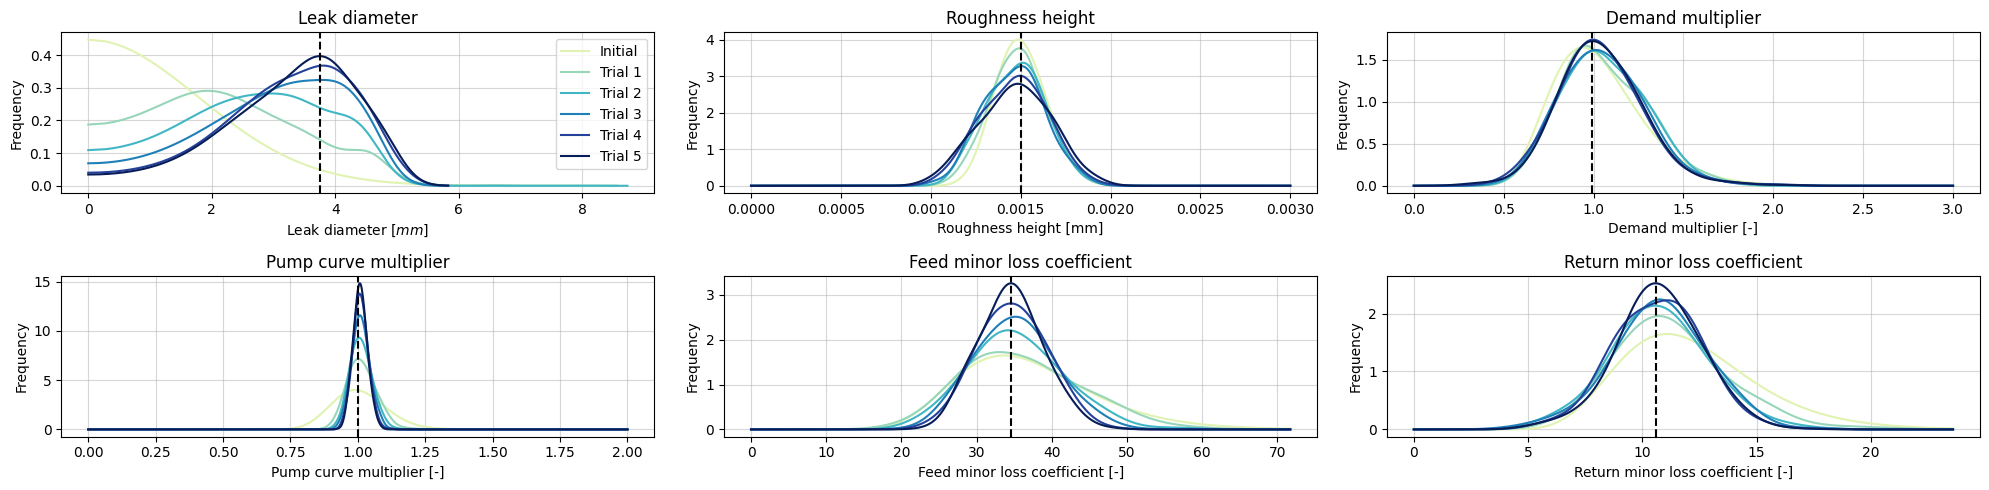

In [22]:
fig, ax = plt.subplots(2, 3, figsize=(20, 5))
ax.flat[0].plot(leak_range[0], leak_area_mean_pdf[0], c=cmap(1), label='Initial')
ax.flat[0].plot(leak_range[1], leak_area_mean_pdf[1], c=cmap(2), label='Trial 1')
ax.flat[0].plot(leak_range[2], leak_area_mean_pdf[2], c=cmap(3), label='Trial 2')
ax.flat[0].plot(leak_range[3], leak_area_mean_pdf[3], c=cmap(4), label='Trial 3')
ax.flat[0].plot(leak_range[4], leak_area_mean_pdf[4], c=cmap(5), label='Trial 4')
ax.flat[0].plot(leak_range[5], leak_area_mean_pdf[5], c=cmap(6), label='Trial 5')
ax.flat[0].set_title('Leak diameter')
ax.flat[0].set_ylabel('Frequency')
ax.flat[0].set_xlabel('Leak diameter [$mm$]')
ax.flat[0].axvline(leak_range[5][np.argmax(leak_area_mean_pdf[5])], linestyle='--', c='k')
ax.flat[0].legend(fontsize=10)

ax.flat[1].plot(mean_roughness * roughness_range[0] * 1000, roughness_mean_pdf[0], c=cmap(1), label='Initial')
ax.flat[1].plot(mean_roughness * roughness_range[1] * 1000, roughness_mean_pdf[1], c=cmap(2), label='Trial 1')
ax.flat[1].plot(mean_roughness * roughness_range[2] * 1000, roughness_mean_pdf[2], c=cmap(3), label='Trial 2')
ax.flat[1].plot(mean_roughness * roughness_range[3] * 1000, roughness_mean_pdf[3], c=cmap(4), label='Trial 3')
ax.flat[1].plot(mean_roughness * roughness_range[4] * 1000, roughness_mean_pdf[4], c=cmap(5), label='Trial 4')
ax.flat[1].plot(mean_roughness * roughness_range[5] * 1000, roughness_mean_pdf[5], c=cmap(6), label='Trial 5')
ax.flat[1].set_title('Roughness height')
ax.flat[1].set_ylabel('Frequency')
ax.flat[1].set_xlabel('Roughness height [mm]')
ax.flat[1].axvline(mean_roughness * 1000, linestyle='--', c='k')

ax.flat[2].plot(demand_range[0], demand_mean_pdf[0], c=cmap(1), label='Initial')
ax.flat[2].plot(demand_range[1], demand_mean_pdf[1], c=cmap(2), label='Trial 1')
ax.flat[2].plot(demand_range[2], demand_mean_pdf[2], c=cmap(3), label='Trial 2')
ax.flat[2].plot(demand_range[3], demand_mean_pdf[3], c=cmap(4), label='Trial 3')
ax.flat[2].plot(demand_range[4], demand_mean_pdf[4], c=cmap(5), label='Trial 4')
ax.flat[2].plot(demand_range[5], demand_mean_pdf[5], c=cmap(6), label='Trial 5')
ax.flat[2].set_title('Demand multiplier')
ax.flat[2].set_ylabel('Frequency')
ax.flat[2].set_xlabel('Demand multiplier [-]')
ax.flat[2].axvline(demand_range[5][np.argmax(demand_mean_pdf[5])], linestyle='--', c='k')

ax.flat[3].plot(pump_range[0], pump_mean_pdf[0], c=cmap(1))
ax.flat[3].plot(pump_range[1], pump_mean_pdf[1], c=cmap(2))
ax.flat[3].plot(pump_range[2], pump_mean_pdf[2], c=cmap(3))
ax.flat[3].plot(pump_range[3], pump_mean_pdf[3], c=cmap(4))
ax.flat[3].plot(pump_range[4], pump_mean_pdf[4], c=cmap(5))
ax.flat[3].plot(pump_range[5], pump_mean_pdf[5], c=cmap(6))
ax.flat[3].set_title('Pump curve multiplier')
ax.flat[3].set_ylabel('Frequency')
ax.flat[3].set_xlabel('Pump curve multiplier [-]')
ax.flat[3].axvline(1., linestyle='--', c='k')

ax.flat[4].plot(feed_minor_loss * feed_minor_range[0], feed_minor_mean_pdf[0], c=cmap(1))
ax.flat[4].plot(feed_minor_loss * feed_minor_range[1], feed_minor_mean_pdf[1], c=cmap(2))
ax.flat[4].plot(feed_minor_loss * feed_minor_range[2], feed_minor_mean_pdf[2], c=cmap(3))
ax.flat[4].plot(feed_minor_loss * feed_minor_range[3], feed_minor_mean_pdf[3], c=cmap(4))
ax.flat[4].plot(feed_minor_loss * feed_minor_range[4], feed_minor_mean_pdf[4], c=cmap(5))
ax.flat[4].plot(feed_minor_loss * feed_minor_range[5], feed_minor_mean_pdf[5], c=cmap(6))
ax.flat[4].set_title('Feed minor loss coefficient')
ax.flat[4].set_ylabel('Frequency')
ax.flat[4].set_xlabel('Feed minor loss coefficient [-]')
ax.flat[4].axvline(feed_minor_loss * feed_minor_range[5][np.argmax(feed_minor_mean_pdf[5])], linestyle='--', c='k')

ax.flat[5].plot(return_minor_loss * return_minor_range[0], return_minor_mean_pdf[0], c=cmap(1))
ax.flat[5].plot(return_minor_loss * return_minor_range[1], return_minor_mean_pdf[1], c=cmap(2))
ax.flat[5].plot(return_minor_loss * return_minor_range[2], return_minor_mean_pdf[2], c=cmap(3))
ax.flat[5].plot(return_minor_loss * return_minor_range[3], return_minor_mean_pdf[3], c=cmap(4))
ax.flat[5].plot(return_minor_loss * return_minor_range[4], return_minor_mean_pdf[4], c=cmap(5))
ax.flat[5].plot(return_minor_loss * return_minor_range[5], return_minor_mean_pdf[5], c=cmap(6))
ax.flat[5].set_title('Return minor loss coefficient')
ax.flat[5].set_ylabel('Frequency')
ax.flat[5].set_xlabel('Return minor loss coefficient [-]')
ax.flat[5].axvline(return_minor_loss * return_minor_range[5][np.argmax(return_minor_mean_pdf[5])], linestyle='--', c='k')
plt.tight_layout()

for i in range(6):
    ax.flat[i].grid(alpha=0.5)

plt.savefig('../img/fig6.png', dpi=200, bbox_inches='tight')

In [23]:
leak_range[-1][np.argmax(leak_area_mean_pdf[-1])]

3.75018662321775

In [24]:
np.trapz(leak_area_mean_pdf[-1] * leak_range[-1], leak_range[-1])

3.255250037968483

In [25]:
1000 * mean_roughness * roughness_range[-1][np.argmax(roughness_mean_pdf[-1])]

0.0014834834834834834

In [26]:
1000 * mean_roughness * np.trapz(roughness_mean_pdf[-1] * roughness_range[-1], roughness_range[-1])

0.0014694785375179657

In [27]:
demand_range[-1][np.argmax(demand_mean_pdf[-1])]

0.993993993993994

In [28]:
np.trapz(demand_mean_pdf[-1] * demand_range[-1], demand_range[-1])

1.0413616475012737

In [29]:
pump_range[-1][np.argmax(pump_mean_pdf[-1])]

1.007007007007007

In [30]:
np.trapz(pump_mean_pdf[-1] * pump_range[-1], pump_range[-1])

1.0086388971560407

In [31]:
feed_minor_loss * feed_minor_range[-1][np.argmax(feed_minor_mean_pdf[-1])]

34.61329329329329

In [32]:
feed_minor_loss * np.trapz(feed_minor_mean_pdf[-1] * feed_minor_range[-1], feed_minor_range[-1])

34.57846906404688

In [33]:
return_minor_loss * return_minor_range[-1][np.argmax(return_minor_mean_pdf[-1])]

10.583383383383383

In [34]:
return_minor_loss * np.trapz(return_minor_mean_pdf[-1] * return_minor_range[-1], return_minor_range[-1])

10.741566235346957